### **1. Import Libraries**


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from pathlib import Path
%matplotlib inline
print("Libraries imported successfully!")

Libraries imported successfully!


### **2. Read Dataset**

In [12]:
script_dir=Path.cwd()
file_path="../data/gold_price_data.csv"
df = pd.read_csv(file_path)
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (1718, 81)


,Date,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
0,2011-12-15,154.740005,154.949997,151.710007,152.330002,152.330002,21521900,123.029999,123.199997,121.989998,...,51.570000,51.680000,48.973877,20605600,36.900002,36.939999,36.049999,36.130001,36.130001,12616700
1,2011-12-16,154.309998,155.369995,153.899994,155.229996,155.229996,18124300,122.230003,122.949997,121.300003,...,52.040001,52.680000,49.921513,16285400,36.180000,36.500000,35.730000,36.270000,36.270000,12578800
2,2011-12-19,155.479996,155.860001,154.360001,154.869995,154.869995,12547200,122.059998,122.320000,120.029999,...,51.029999,51.169998,48.490578,15120200,36.389999,36.450001,35.930000,36.200001,36.200001,7418200
3,2011-12-20,156.820007,157.429993,156.580002,156.979996,156.979996,9136300,122.180000,124.139999,120.370003,...,52.369999,52.990002,50.215282,11644900,37.299999,37.610001,37.220001,37.560001,37.560001,10041600
4,2011-12-21,156.979996,157.529999,156.130005,157.160004,157.160004,11996100,123.930000,124.360001,122.750000,...,52.419998,52.959999,50.186852,8724300,37.669998,38.240002,37.520000,38.110001,38.110001,10728000


### **3. Explore the Data with Graphs**

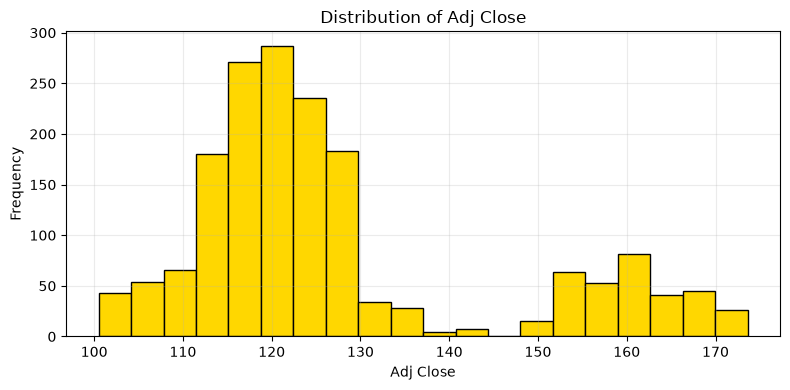

Saved outputs/gold_price_distribution.png


In [20]:
# Histogram of target Gold price (Adj Close)
column_to_plot = "Adj Close"
plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot].dropna(), bins=20, color="gold", edgecolor="black")
plt.title(f"Distribution of {column_to_plot}")
plt.xlabel(column_to_plot)
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("../outputs/gold_price_distribution.png")
plt.show()
print("Saved outputs/gold_price_distribution.png")

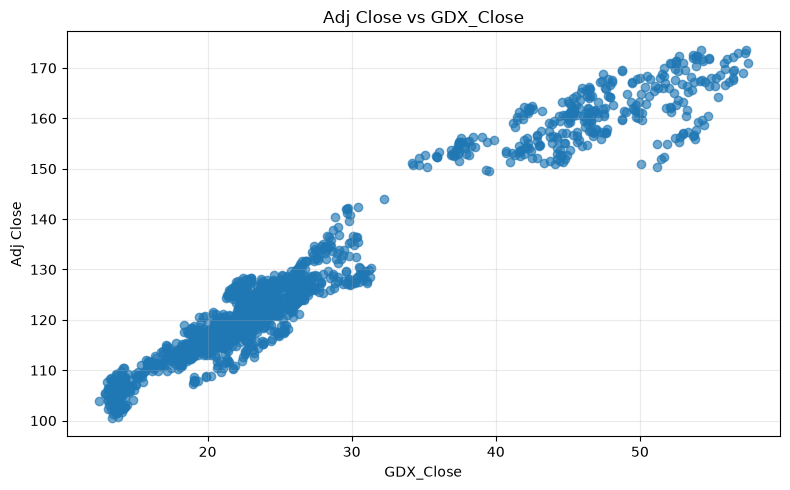

Saved outputs/feature_vs_gold_scatter.png


In [23]:
# Scatter plot: GDX_Close vs Adj Close
feature_for_plot = "GDX_Close"
target_for_plot = "Adj Close"
plt.figure(figsize=(8, 5))
plt.scatter(df[feature_for_plot], df[target_for_plot], alpha=0.65)
plt.title(f"{target_for_plot} vs {feature_for_plot}")
plt.xlabel(feature_for_plot)
plt.ylabel(target_for_plot)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("../outputs/feature_vs_gold_scatter.png")
plt.show()
print("Saved outputs/feature_vs_gold_scatter.png")

### **4. Preprocess the Data**

In [24]:
df = df.drop_duplicates().copy()

target_column = "Adj Close"
gld_columns = ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]
feature_columns = [col for col in df.columns if col not in gld_columns]

model_df = df[feature_columns + [target_column]].copy()
model_df[target_column] = pd.to_numeric(model_df[target_column], errors="coerce")
model_df = model_df.dropna(subset=[target_column])

X = model_df[feature_columns]
y = model_df[target_column]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Rows available for modelling:", len(model_df))

Input shape: (1718, 74)
Target shape: (1718,)
Rows available for modelling: 1718


### **5. Split into Training and Testing Data**

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 1374
Testing examples: 344
